The main objectives of this notebook are to:

1.Select 10 representative SKUs from different ABC-XYZ demand segments.

2.Prepare the feature-engineered dataset for forecasting.

3.Perform stationarity testing using the Augmented Dickey-Fuller (ADF) test.

4.Split the data chronologically into training and testing sets.

5.Develop a Linear Regression baseline model.

6.Develop an advanced ensemble model for demand forecasting.

7.Evaluate model performance using MAE, RMSE, and MAPE.

In [1]:
# Import necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from statsmodels.tsa.stattools import adfuller

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import mean_absolute_error, mean_squared_error

In [2]:
# Load the feature-engineered dataset
df = pd.read_csv(
    "../data/fmcg_sales_features.csv",
    parse_dates=["date"]
)

# Display dataset information
print("Dataset shape:", df.shape)
print("\nDataset information:")
df.info()

print("\nFirst five observations:")
display(df.head())

Dataset shape: (111690, 15)

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 111690 entries, 0 to 111689
Data columns (total 15 columns):
 #   Column           Non-Null Count   Dtype         
---  ------           --------------   -----         
 0   date             111690 non-null  datetime64[us]
 1   sku_id           111690 non-null  str           
 2   units_sold       111690 non-null  int64         
 3   lag_1            111588 non-null  float64       
 4   lag_7            110976 non-null  float64       
 5   lag_14           110262 non-null  float64       
 6   lag_28           108834 non-null  float64       
 7   lag_30           108630 non-null  float64       
 8   rolling_mean_7   110976 non-null  float64       
 9   rolling_mean_14  110262 non-null  float64       
 10  rolling_mean_28  108834 non-null  float64       
 11  rolling_mean_30  108630 non-null  float64       
 12  day_of_week      111690 non-null  int64         
 13  month            111690 non-null  i

,date,sku_id,units_sold,lag_1,lag_7,lag_14,lag_28,lag_30,rolling_mean_7,rolling_mean_14,rolling_mean_28,rolling_mean_30,day_of_week,month,is_weekend
0,2021-01-01,SKU0001,1118,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4,1,0
1,2021-01-02,SKU0001,2341,1118.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5,1,1
2,2021-01-03,SKU0001,2798,2341.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,6,1,1
3,2021-01-04,SKU0001,2429,2798.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,1,0
4,2021-01-05,SKU0001,1289,2429.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,1,0


In [3]:
# Define the 10 selected SKUs
selected_skus = [
    "SKU0089", "SKU0079", "SKU0045", "SKU0023",
    "SKU0096", "SKU0063", "SKU0006", "SKU0084",
    "SKU0042", "SKU0015"
]

# Filter the feature-engineered dataset
forecast_data = df[df["sku_id"].isin(selected_skus)].copy()

# Check the selected dataset
print("Forecasting dataset shape:", forecast_data.shape)
print("Number of selected SKUs:", forecast_data["sku_id"].nunique())

display(forecast_data.head())

Forecasting dataset shape: (10950, 15)
Number of selected SKUs: 10


,date,sku_id,units_sold,lag_1,lag_7,lag_14,lag_28,lag_30,rolling_mean_7,rolling_mean_14,rolling_mean_28,rolling_mean_30,day_of_week,month,is_weekend
5475,2021-01-01,SKU0006,1146,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4,1,0
5476,2021-01-02,SKU0006,2316,1146.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5,1,1
5477,2021-01-03,SKU0006,2368,2316.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,6,1,1
5478,2021-01-04,SKU0006,2093,2368.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,1,0
5479,2021-01-05,SKU0006,1079,2093.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,1,0


In [4]:
# Check the number of observations for each SKU
sku_counts = forecast_data.groupby("sku_id")["date"].count()

print("Daily observations per SKU:")
display(sku_counts)

# Check missing values in the forecasting dataset
print("\nMissing values:")
display(forecast_data.isnull().sum())

Daily observations per SKU:


sku_id
SKU0006    1095
SKU0015    1095
SKU0023    1095
SKU0042    1095
SKU0045    1095
SKU0063    1095
SKU0079    1095
SKU0084    1095
SKU0089    1095
SKU0096    1095
Name: date, dtype: int64


Missing values:


date                 0
sku_id               0
units_sold           0
lag_1               10
lag_7               70
lag_14             140
lag_28             280
lag_30             300
rolling_mean_7      70
rolling_mean_14    140
rolling_mean_28    280
rolling_mean_30    300
day_of_week          0
month                0
is_weekend           0
dtype: int64

The selected forecasting dataset contains 10,950 observations representing 10 SKUs over three years of daily sales data.

The lag and rolling-average features contain missing values at the beginning of each SKU's time series. These missing values occur because historical observations are unavailable for calculating the initial lag values and rolling averages.



In [5]:
# Define the final six months as the test period
test_start = (
    forecast_data["date"].max()
    - pd.DateOffset(months=6)
    + pd.Timedelta(days=1)
)

# Chronological split
train_data = forecast_data[
    forecast_data["date"] < test_start
].copy()

test_data = forecast_data[
    forecast_data["date"] >= test_start
].copy()

print("Training period:",
      train_data["date"].min(), "to", train_data["date"].max())

print("Testing period:",
      test_data["date"].min(), "to", test_data["date"].max())

print("\nTraining shape:", train_data.shape)
print("Testing shape:", test_data.shape)

Training period: 2021-01-01 00:00:00 to 2023-06-30 00:00:00
Testing period: 2023-07-01 00:00:00 to 2023-12-31 00:00:00

Training shape: (9110, 15)
Testing shape: (1840, 15)


In [6]:
# Perform ADF test for each selected SKU
adf_results = []

for sku in selected_skus:
    sku_demand = (
        train_data[train_data["sku_id"] == sku]["units_sold"]
    )

    adf_result = adfuller(sku_demand)

    adf_results.append({
        "sku_id": sku,
        "ADF Statistic": adf_result[0],
        "p-value": adf_result[1],
        "Critical Value (5%)": adf_result[4]["5%"],
        "Stationarity": (
            "Stationary" if adf_result[1] < 0.05
            else "Non-stationary"
        )
    })

adf_results = pd.DataFrame(adf_results)

display(adf_results)

,sku_id,ADF Statistic,p-value,Critical Value (5%),Stationarity
0,SKU0089,-5.630188,1.093995e-06,-2.864793,Stationary
1,SKU0079,-30.399032,0.000000e+00,-2.864721,Stationary
2,SKU0045,-7.953349,3.083613e-12,-2.864742,Stationary
3,SKU0023,-3.576883,6.218663e-03,-2.864771,Stationary
4,SKU0096,-5.699230,7.745058e-07,-2.864793,Stationary
5,SKU0063,-9.196551,2.055298e-15,-2.864753,Stationary
6,SKU0006,-3.434989,9.822369e-03,-2.864771,Stationary
7,SKU0084,-5.804345,4.553280e-07,-2.864793,Stationary
8,SKU0042,-3.090029,2.729993e-02,-2.864793,Stationary
9,SKU0015,-2.361245,1.529748e-01,-2.864793,Non-stationary


The Augmented Dickey-Fuller (ADF) test was conducted on the training data for the ten selected SKUs using a 5% significance level.

The results indicated that nine SKUs were stationary, with p-values below 0.05. SKU0015 was non-stationary, recording a p-value of approximately 0.153.

These findings suggest that most selected demand series provide evidence of stationarity. However, SKU0015 may require additional investigation or transformation before applying forecasting methods that assume stationarity.


In [7]:
# Define model features
features = [
    "lag_1",
    "lag_7",
    "lag_14",
    "lag_28",
    "lag_30",
    "rolling_mean_7",
    "rolling_mean_14",
    "rolling_mean_28",
    "rolling_mean_30",
    "day_of_week",
    "month",
    "is_weekend"
]

target = "units_sold"

# Remove rows with missing feature values
train_model = train_data.dropna(subset=features).copy()
test_model = test_data.dropna(subset=features).copy()

print("Training data shape:", train_model.shape)
print("Testing data shape:", test_model.shape)

print("\nMissing values in training data:",
      train_model[features].isnull().sum().sum())

print("Missing values in testing data:",
      test_model[features].isnull().sum().sum())

Training data shape: (8810, 15)
Testing data shape: (1840, 15)

Missing values in training data: 0
Missing values in testing data: 0


In [8]:
# Define training and testing features
X_train = train_model[features]
y_train = train_model[target]

X_test = test_model[features]
y_test = test_model[target]

# Train the Linear Regression model
lr_model = LinearRegression()
lr_model.fit(X_train, y_train)

# Generate predictions
lr_predictions = lr_model.predict(X_test)

# Evaluate model performance
lr_mae = mean_absolute_error(y_test, lr_predictions)
lr_rmse = np.sqrt(mean_squared_error(y_test, lr_predictions))

# Calculate MAPE, excluding zero actual values
non_zero = y_test != 0

lr_mape = np.mean(
    np.abs(
        (y_test[non_zero] - lr_predictions[non_zero])
        / y_test[non_zero]
    )
) * 100

print("Linear Regression Performance")
print("MAE:", lr_mae)
print("RMSE:", lr_rmse)
print("MAPE:", lr_mape, "%")

Linear Regression Performance
MAE: 124.68496859198511
RMSE: 213.30679645296243
MAPE: 22.061221587840624 %


In [9]:
# Train the Random Forest model
rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

# Generate predictions
rf_predictions = rf_model.predict(X_test)

# Evaluate performance
rf_mae = mean_absolute_error(y_test, rf_predictions)
rf_rmse = np.sqrt(mean_squared_error(y_test, rf_predictions))

non_zero = y_test != 0

rf_mape = np.mean(
    np.abs(
        (y_test[non_zero] - rf_predictions[non_zero])
        / y_test[non_zero]
    )
) * 100

print("Random Forest Performance")
print("MAE:", rf_mae)
print("RMSE:", rf_rmse)
print("MAPE:", rf_mape, "%")

Random Forest Performance
MAE: 126.94546195652174
RMSE: 221.0615725291849
MAPE: 18.352450354914396 %


In [10]:
model_comparison = pd.DataFrame({
    "Model": ["Linear Regression", "Random Forest"],
    "MAE": [lr_mae, rf_mae],
    "RMSE": [lr_rmse, rf_rmse],
    "MAPE (%)": [lr_mape, rf_mape]
})

display(model_comparison)

,Model,MAE,RMSE,MAPE (%)
0,Linear Regression,124.684969,213.306796,22.061222
1,Random Forest,126.945462,221.061573,18.352450


In [11]:
# Combine actual and predicted values
results = test_model[["date", "sku_id", "units_sold"]].copy()

results["lr_prediction"] = lr_predictions
results["rf_prediction"] = rf_predictions

# Calculate performance metrics for each SKU
sku_performance = []

for sku, group in results.groupby("sku_id"):

    actual = group["units_sold"]
    lr_pred = group["lr_prediction"]
    rf_pred = group["rf_prediction"]

    non_zero = actual != 0

    sku_performance.append({
        "sku_id": sku,
        "LR_MAE": mean_absolute_error(actual, lr_pred),
        "RF_MAE": mean_absolute_error(actual, rf_pred),
        "LR_MAPE": (
            np.mean(np.abs((actual[non_zero] - lr_pred[non_zero])
                           / actual[non_zero])) * 100
        ),
        "RF_MAPE": (
            np.mean(np.abs((actual[non_zero] - rf_pred[non_zero])
                           / actual[non_zero])) * 100
        )
    })

sku_performance = pd.DataFrame(sku_performance)

display(sku_performance.round(2))

,sku_id,LR_MAE,RF_MAE,LR_MAPE,RF_MAPE
0,SKU0006,324.84,345.50,20.35,22.39
1,SKU0015,34.55,13.07,23.56,9.05
2,SKU0023,220.60,238.60,23.67,25.99
3,SKU0042,37.45,9.90,45.53,13.24
4,SKU0045,187.53,199.08,27.80,29.86
5,SKU0063,122.78,140.96,22.36,27.26
6,SKU0079,150.06,162.34,25.41,28.04
7,SKU0084,33.61,23.20,13.28,9.38
8,SKU0089,40.97,38.19,10.42,9.74
9,SKU0096,94.46,98.61,8.23,8.57


Two regression models, Linear Regression and Random Forest, were developed to forecast daily demand for the ten selected SKUs. Both models were trained using the same training dataset and evaluated on the final six months of observations.

The overall evaluation produced the following results:

Linear Regression: MAE = 124.68, RMSE = 213.31, MAPE = 22.06%.
Random Forest: MAE = 126.95, RMSE = 221.06, MAPE = 18.35%.

Linear Regression achieved lower MAE and RMSE, while Random Forest recorded a lower MAPE.

SKU-level evaluation further revealed differences in model performance across products. Random Forest achieved lower MAPE for seven of the ten SKUs, whereas Linear Regression achieved lower MAE for six SKUs.

These findings indicate that neither model consistently outperformed the other across all evaluation metrics and products. Model selection should therefore consider the forecasting requirements and performance of individual SKUs.


In [12]:
# Extract Random Forest feature importance
feature_importance = pd.DataFrame({
    "Feature": features,
    "Importance": rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

display(feature_importance)

,Feature,Importance
5,rolling_mean_7,0.304951
7,rolling_mean_28,0.281153
6,rolling_mean_14,0.142625
8,rolling_mean_30,0.141079
4,lag_30,0.021927
0,lag_1,0.020930
1,lag_7,0.019603
2,lag_14,0.019568
3,lag_28,0.018409
9,day_of_week,0.012291


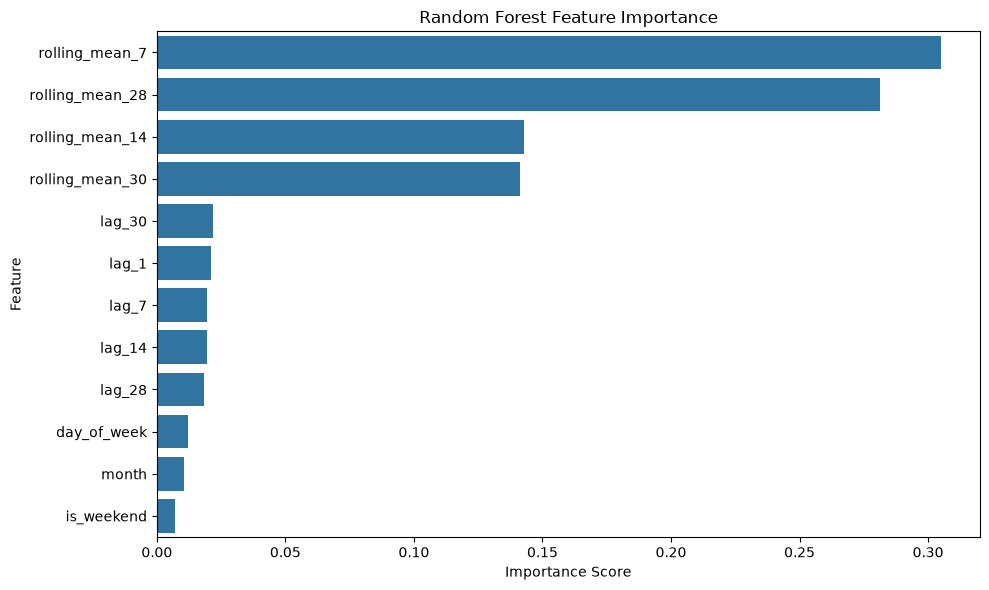

In [13]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=feature_importance,
    x="Importance",
    y="Feature"
)

plt.title("Random Forest Feature Importance")
plt.xlabel("Importance Score")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

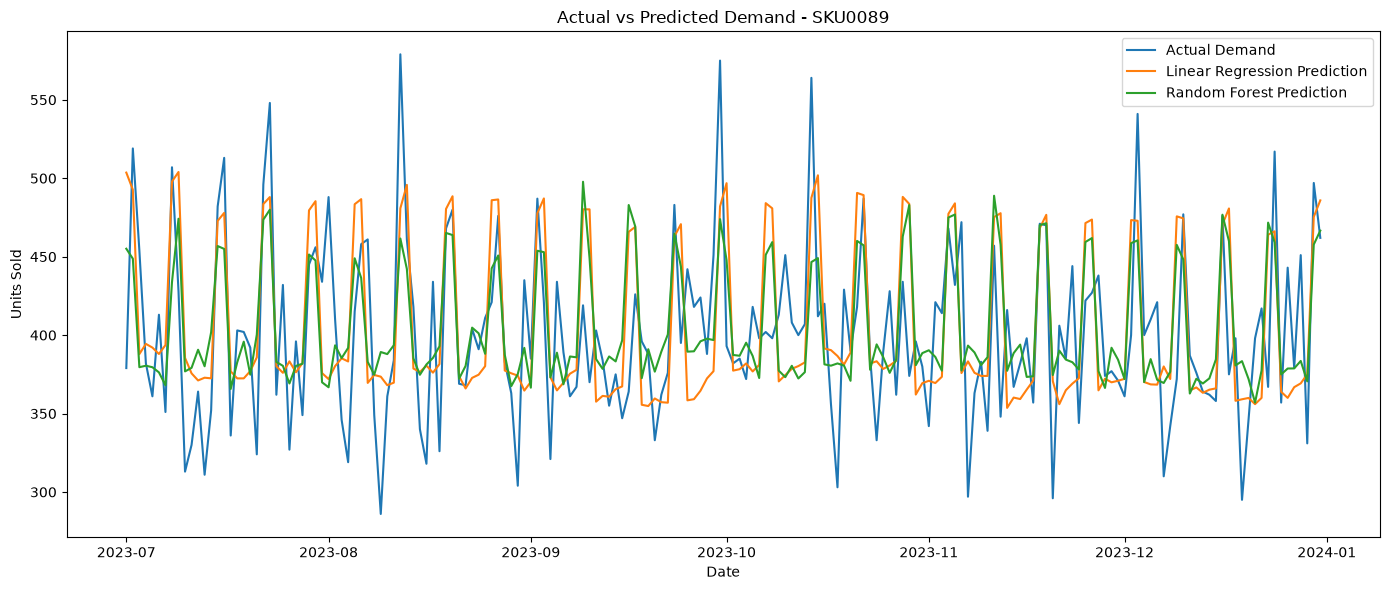

In [14]:
sku_to_plot = "SKU0089"

sku_results = results[
    results["sku_id"] == sku_to_plot
].sort_values("date")

plt.figure(figsize=(14, 6))

plt.plot(
    sku_results["date"],
    sku_results["units_sold"],
    label="Actual Demand"
)

plt.plot(
    sku_results["date"],
    sku_results["lr_prediction"],
    label="Linear Regression Prediction"
)

plt.plot(
    sku_results["date"],
    sku_results["rf_prediction"],
    label="Random Forest Prediction"
)

plt.title(f"Actual vs Predicted Demand - {sku_to_plot}")
plt.xlabel("Date")
plt.ylabel("Units Sold")
plt.legend()
plt.tight_layout()
plt.show()

Actual vs Predicted Demand: Key Observations

1. Demand fluctuations

The actual demand series exhibits frequent fluctuations, with sharp increases and decreases throughout the six-month testing period. This highlights the variability of daily product demand.

2. Model performance comparison

Random Forest: The model appears to capture some of the fluctuations in actual demand more closely, suggesting that it can represent non-linear demand patterns.

Linear Regression: Its predictions appear smoother and less responsive to some of the sharper changes in actual demand.

However, the visual comparison should be considered alongside the evaluation metrics. Linear Regression achieved lower MAE and RMSE, while Random Forest achieved a lower MAPE. Therefore, neither model consistently outperformed the other across all evaluation measures.

3. Demand trend and seasonality

The chart provides an opportunity to examine changes in the overall demand level and recurring patterns during the testing period. However, a six-month visual comparison alone is insufficient to establish a consistent seasonal pattern.

